## EXERCISE 5 - FEATURE ENGINEERING



*   nadhila alya azzahra (051)
*   gloria jesika oktoniar pardosi (148)



In [5]:
import warnings
warnings.filterwarnings(action='ignore')

In [6]:
!pip install gensim umap-learn

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, defaultdict

df = pd.read_csv('review_mytelkomsel_bersih.csv')
print("Sebelum dropna :", df.shape)

# review yg isinya kosong setelah preprocessing (mis. cuma emoji) dibuang
df = df.dropna(subset=['Teks_Bersih'])
df = df[df['Teks_Bersih'].str.strip() != ''].reset_index(drop=True)
print("Setelah dropna :", df.shape)

df_pre = df['Teks_Bersih']
df_pre.info()

Sebelum dropna : (2000, 5)
Setelah dropna : (1886, 5)
<class 'pandas.core.series.Series'>
RangeIndex: 1886 entries, 0 to 1885
Series name: Teks_Bersih
Non-Null Count  Dtype 
--------------  ----- 
1886 non-null   object
dtypes: object(1)
memory usage: 14.9+ KB


**1. One Hot Encoding**
: nilai 1 jika kata muncul di review, 0 jika tidak (frekuensi tidak dihitung).

In [8]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(binary=True)
X = vectorizer.fit_transform(df_pre)
df_ohe = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())
df_ohe

,01,10,100,1000,10000,100gb,100k,100mb,10gb,10rb,...,wow,woy,xl,yaa,yahudi,yak,yg,you,youtube,zaman
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1881,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1882,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1883,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1884,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [9]:
print("Shape            :", df_ohe.shape, "-> (jumlah review, ukuran vocabulary)")
print("Nilai unik       :", np.unique(X.data))
print(f"Sparsity         : {(1 - X.nnz / (X.shape[0] * X.shape[1])) * 100:.2f}% bernilai 0")
print("\nContoh review    :", df_pre.iloc[0])
kolom_aktif = df_ohe.columns[df_ohe.iloc[0] > 0]
df_ohe.loc[[0], kolom_aktif]

Shape            : (1886, 1356) -> (jumlah review, ukuran vocabulary)
Nilai unik       : [1]
Sparsity         : 99.41% bernilai 0

Contoh review    : jaring nauzubillah lot udh yg 70gb saking lot tri akses nonton biar aja rugi yg penting ngk lot


,70gb,aja,akses,biar,jaring,lot,nauzubillah,ngk,nonton,penting,rugi,saking,tri,udh,yg
0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1


**2. Bag of Words** :
seperti one hot tpi yang dihitung adalah jumlah kemunculan kata tiap reviewnya

In [10]:
vectorizer = CountVectorizer()
X_bow = vectorizer.fit_transform(df_pre)
df_bow = pd.DataFrame(X_bow.toarray(), columns=vectorizer.get_feature_names_out())
df_bow

,01,10,100,1000,10000,100gb,100k,100mb,10gb,10rb,...,wow,woy,xl,yaa,yahudi,yak,yg,you,youtube,zaman
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,2,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1881,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1882,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1883,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1884,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Shape  : (1886, 1356)
Sparsity : 99.41%

Contoh review dengan kata berulang:
  jaring nauzubillah lot udh yg 70gb saking lot tri akses nonton biar aja rugi yg penting ngk lot
  harga internet internet mahalmahal kartu khusus orang kaya harga banding orang kaya orang miskin harga langit
  harga doang lot gua ga masalah kalo kualitas bagus udah kualitas jelek blok


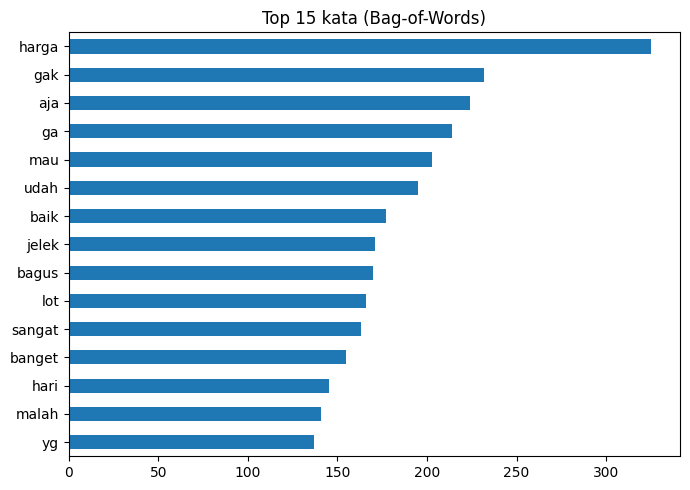

In [11]:
print("Shape  :", df_bow.shape)
print(f"Sparsity : {(1 - X_bow.nnz / (X_bow.shape[0] * X_bow.shape[1])) * 100:.2f}%")

# review yang punya kata berulang -> bedanya dengan one hot terlihat di sini
ada_ulang = df_bow[(df_bow > 1).any(axis=1)].index[:3]
print("\nContoh review dengan kata berulang:")
for i in ada_ulang:
    print(" ", df_pre.iloc[i])

top_bow = df_bow.sum().sort_values(ascending=False).head(15)
top_bow.sort_values().plot(kind='barh', figsize=(7, 5), title='Top 15 kata (Bag-of-Words)')
plt.tight_layout(); plt.show()

**3. TF-IDF**

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer()
X_tfidf = vectorizer.fit_transform(df_pre)
df_tfidf = pd.DataFrame(X_tfidf.toarray(), columns=vectorizer.get_feature_names_out())
df_tfidf

,01,10,100,1000,10000,100gb,100k,100mb,10gb,10rb,...,wow,woy,xl,yaa,yahudi,yak,yg,you,youtube,zaman
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.303707,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1881,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
1882,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
1883,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
1884,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0


In [13]:
# IDF: kecil = kata umum, besar = kata langka
idf = pd.Series(vectorizer.idf_, index=vectorizer.get_feature_names_out())
print("IDF terkecil (paling umum) :", idf.sort_values().head(8).round(2).to_dict())
print("IDF terbesar (paling langka):", idf.sort_values(ascending=False).head(5).round(2).to_dict())

# bandingkan top kata BoW vs TF-IDF
top_tfidf = df_tfidf.mean().sort_values(ascending=False).head(15)
pd.DataFrame({'Top BoW': top_bow.index, 'Top TF-IDF': top_tfidf.index})

IDF terkecil (paling umum) : {'harga': 2.94, 'aja': 3.28, 'mau': 3.36, 'gak': 3.38, 'bagus': 3.44, 'ga': 3.46, 'baik': 3.47, 'jelek': 3.5}
IDF terbesar (paling langka): {'27': 7.85, 'open': 7.85, 'qiris': 7.85, 'gembor': 7.85, 'buru': 7.85}


,Top BoW,Top TF-IDF
0,harga,bagus
1,gak,baik
2,aja,sangat
3,ga,harga
4,mau,lot
5,udah,mantap
6,baik,jelek
7,jelek,gak
8,bagus,ga
9,lot,aja


In [14]:
# kata khas review rating rendah (1-2) vs tinggi (4-5)
def top_terms(mask, n=10):
    return df_tfidf[mask.values].mean().sort_values(ascending=False).head(n).index

pd.DataFrame({
    'Rating 1-2': top_terms(df['Rating'] <= 2),
    'Rating 4-5': top_terms(df['Rating'] >= 4)
})

,Rating 1-2,Rating 4-5
0,harga,bagus
1,lot,mantap
2,jelek,baik
3,gak,sangat
4,ga,bantu
5,mau,puas
6,aja,good
7,buruk,keren
8,banget,oke
9,apk,mudah


**Tokenize Sentence**

In [15]:
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [16]:
from nltk import word_tokenize
from tqdm import tqdm

sentences = [word_tokenize(review.lower()) for review in tqdm(df_pre)]
sentences[:5]

100%|██████████| 1886/1886 [00:00<00:00, 4616.62it/s]


[['jaring',
  'nauzubillah',
  'lot',
  'udh',
  'yg',
  '70gb',
  'saking',
  'lot',
  'tri',
  'akses',
  'nonton',
  'biar',
  'aja',
  'rugi',
  'yg',
  'penting',
  'ngk',
  'lot'],
 ['harga', 'paket'],
 ['harga',
  'internet',
  'internet',
  'mahalmahal',
  'kartu',
  'khusus',
  'orang',
  'kaya',
  'harga',
  'banding',
  'orang',
  'kaya',
  'orang',
  'miskin',
  'harga',
  'langit'],
 ['laku',
  'beli',
  'internet',
  'alas',
  'koneksi',
  'padahal',
  'bagus2',
  'aja',
  'pakai',
  'wifi',
  'bahkan',
  'pagi',
  'malam',
  'tetap'],
 ['sumpah', 'ga', 'daerah', 'gw', 'parah', 'jelek', 'nyaa', 'penuh', 'ngleg']]

**4. Build Word2Vec Model**

In [17]:
import gensim.models
# 1. Train Model
model = gensim.models.Word2Vec(sentences, min_count=1, vector_size=100, window=5, sg=0)

In [18]:
# 2. Save Model
model.save('review_telkomsel.w2v')

In [19]:
# 3. Load Model
model = gensim.models.Word2Vec.load('review_telkomsel.w2v')

In [20]:
# 4. Model Information
w2v = model.wv
w2v.index_to_key[:10]

['harga', 'gak', 'aja', 'ga', 'mau', 'udah', 'baik', 'jelek', 'bagus', 'lot']

In [21]:
w2v.vectors.shape, w2v.vector_size # size of vector

((1379, 100), 100)

In [22]:
# kata paling mirip (pakai kata yg ada di 10 kata teratas vocab-mu)
kata = w2v.index_to_key[0]
print("Kata :", kata)
w2v.similar_by_key(kata)

Kata : harga


[('buat', 0.999717652797699),
 ('bulan', 0.9997165203094482),
 ('jadi', 0.9997100234031677),
 ('hari', 0.9997096061706543),
 ('pulsa', 0.9996947050094604),
 ('masa', 0.9996750950813293),
 ('gak', 0.9996602535247803),
 ('ga', 0.9996596574783325),
 ('padahal', 0.9996481537818909),
 ('pakai', 0.999638557434082)]

In [23]:
# 5. FE result
def get_document_vector(tokens, model):
    valid_vectors = [model.wv[word] for word in tokens if word in model.wv]
    if not valid_vectors:                       # jaga-jaga kalau review tidak punya kata valid
        return np.zeros(model.vector_size)
    return np.mean(valid_vectors, axis=0)

X_w2v = np.array([get_document_vector(doc, model) for doc in sentences])
pd.DataFrame(X_w2v)

,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
0,-0.051664,0.167054,-0.014658,-0.016611,0.012881,-0.322376,0.137984,0.324710,-0.065921,-0.078003,...,0.231152,0.136007,-0.069335,0.063751,0.295507,0.223879,0.178323,-0.212922,0.005387,-0.090557
1,-0.096293,0.327706,-0.021499,-0.026868,0.015556,-0.622285,0.273996,0.631141,-0.126384,-0.148302,...,0.449036,0.256877,-0.133282,0.120949,0.575409,0.439517,0.336375,-0.421611,0.000177,-0.176760
2,-0.059960,0.204891,-0.014279,-0.018369,0.013482,-0.393535,0.171695,0.395426,-0.080072,-0.093555,...,0.280888,0.161942,-0.085529,0.077667,0.356525,0.274757,0.216922,-0.264074,0.006773,-0.108991
3,-0.054125,0.174981,-0.016110,-0.018221,0.011651,-0.337797,0.146715,0.340352,-0.070525,-0.080549,...,0.244504,0.141445,-0.075894,0.063426,0.307451,0.240161,0.191671,-0.230551,0.003398,-0.097252
4,-0.047632,0.161856,-0.009287,-0.020008,0.010389,-0.310505,0.135309,0.315150,-0.062985,-0.077930,...,0.226210,0.128196,-0.068952,0.059318,0.285044,0.217791,0.173831,-0.210625,0.003056,-0.093533
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1881,0.002126,0.006405,-0.005393,-0.008538,0.007804,-0.015649,0.009556,0.008861,-0.005690,-0.012867,...,0.004126,0.009041,0.001692,-0.003952,0.014002,0.017677,0.012708,-0.018737,0.006439,-0.001878
1882,-0.017695,0.038354,-0.008078,-0.005451,0.003160,-0.062235,0.016762,0.065013,-0.018945,-0.023428,...,0.037099,0.021432,-0.003517,0.017393,0.056714,0.038923,0.038231,-0.038236,0.008749,-0.017120
1883,-0.017695,0.038354,-0.008078,-0.005451,0.003160,-0.062235,0.016762,0.065013,-0.018945,-0.023428,...,0.037099,0.021432,-0.003517,0.017393,0.056714,0.038923,0.038231,-0.038236,0.008749,-0.017120
1884,-0.074602,0.226813,-0.013358,-0.014266,0.020934,-0.409871,0.187077,0.413064,-0.090410,-0.094933,...,0.294187,0.172027,-0.088499,0.078422,0.387460,0.298416,0.233795,-0.270667,0.009338,-0.124722


**VISUALIZE**

In [24]:
from umap import UMAP
import plotly.express as px

In [25]:
X = UMAP().fit_transform(w2v.vectors)

df2 = pd.DataFrame(X, columns=['umap1', 'umap2'])
df2['word'] = w2v.index_to_key

fig = px.scatter(df2, x='umap1', y='umap2', text='word')
fig.update_traces(textposition='top center')
fig.update_layout(height=800, title_text='Word2Vec Visualization')
fig.show()

**5. Build FastText Model**

In [26]:
import gensim.models
#1. build model
model_fasttext = gensim.models.FastText(sentences, min_count=1,
                                        vector_size=100, window=5,
                                        min_n=3, max_n=6,
                                        sg=1, epochs=10)

In [27]:
# 2. save model
model_fasttext.save('review_telkomsel.fasttext')

In [28]:
# 3. load model
model_fasttext = gensim.models.FastText.load('review_telkomsel.fasttext')

In [29]:
# 4. model information
fastext = model_fasttext.wv
fastext.index_to_key[:10]

['harga', 'gak', 'aja', 'ga', 'mau', 'udah', 'baik', 'jelek', 'bagus', 'lot']

In [30]:
fastext.vectors.shape

(1379, 100)

In [31]:
fastext.similar_by_key(w2v.index_to_key[0])

[('hama', 0.9921251535415649),
 ('harap', 0.9913622736930847),
 ('cuman', 0.9911725521087646),
 ('makin', 0.9910621047019958),
 ('jari', 0.9907386898994446),
 ('internetan', 0.9906953573226929),
 ('smakin', 0.9906278252601624),
 ('internetnya', 0.9903540015220642),
 ('internet', 0.9903268814086914),
 ('ku', 0.9899432063102722)]

In [32]:
# 5. FE result
X_ft = np.array([get_document_vector(doc, model_fasttext) for doc in sentences])
pd.DataFrame(X_ft)

,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
0,-0.154072,-0.046408,0.162161,-0.033660,0.209994,-0.121520,0.187896,-0.183521,0.115746,0.105660,...,-0.199402,0.302489,0.031153,0.051279,-0.161428,0.174741,0.023741,0.016027,-0.064836,0.451525
1,-0.140918,-0.024625,0.170305,-0.040280,0.167929,-0.156318,0.183713,-0.186866,0.099672,0.133936,...,-0.187388,0.320383,0.026806,0.052803,-0.134451,0.175162,0.015505,-0.008731,-0.051160,0.492162
2,-0.142650,-0.035712,0.163729,-0.042008,0.179719,-0.125933,0.206111,-0.200920,0.110393,0.113705,...,-0.198777,0.309325,0.021311,0.050360,-0.163316,0.174811,0.014723,-0.003053,-0.059644,0.470391
3,-0.157084,-0.055759,0.169656,-0.047009,0.211800,-0.115187,0.174744,-0.173491,0.094258,0.133724,...,-0.196734,0.320003,0.040898,0.057917,-0.156771,0.193497,0.020691,-0.003019,-0.063070,0.469321
4,-0.155078,-0.041172,0.162343,-0.013687,0.208910,-0.134930,0.185503,-0.185861,0.132650,0.069667,...,-0.181119,0.286455,0.017485,0.038154,-0.151674,0.154801,0.018680,0.033679,-0.064369,0.420759
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1881,-0.102392,-0.030836,0.112199,-0.026874,0.136515,-0.082545,0.124420,-0.118283,0.075702,0.076032,...,-0.136320,0.207383,0.023583,0.037746,-0.104026,0.118992,0.011776,0.006170,-0.042043,0.307395
1882,-0.124827,-0.043112,0.133401,-0.042491,0.171637,-0.098143,0.160468,-0.156093,0.080468,0.116553,...,-0.174468,0.274338,0.028573,0.051844,-0.143652,0.164020,0.021660,-0.006632,-0.052623,0.403402
1883,-0.124827,-0.043112,0.133401,-0.042491,0.171637,-0.098143,0.160468,-0.156093,0.080468,0.116553,...,-0.174468,0.274338,0.028573,0.051844,-0.143652,0.164020,0.021660,-0.006632,-0.052623,0.403402
1884,-0.159957,-0.044094,0.193594,-0.021171,0.232229,-0.120209,0.204617,-0.215342,0.125557,0.114218,...,-0.220229,0.310857,0.037435,0.039622,-0.180856,0.177268,0.019036,0.010524,-0.076904,0.490186


**VISUALIZE**

In [33]:
X = UMAP().fit_transform(fastext.vectors)

df2 = pd.DataFrame(X, columns=['umap1', 'umap2'])
df2['word'] = fastext.index_to_key

fig = px.scatter(df2, x='umap1', y='umap2', text='word')
fig.update_traces(textposition='top center')
fig.update_layout(height=800, title_text='fastext Visualization')
fig.show()

**ANALISIS:**

**1. One Hot Encoding.** Hasilnya matriks 1886 x 1356 yang berisi 0/1, sparsity 99,41%. Hanya menandai kata ada atau tidak,
jadi tidak tahu seberapa sering kata muncul dan tidak ada kemiripan antar kata.

**2. Bag-of-Words.** Ukuran dan sparsity sama dengan one hot, tapi nilainya jumlah kemunculan. Terlihat pada review
yang punya kata berulang (mis. 'lot', 'harga', 'orang'). Kata paling sering: 'harga', 'gak', 'aja', 'ga', 'mau',
yang sebagian besar kata umum, bukan kata yang membedakan sentimen.

**3. TF-IDF.** Kata umum seperti 'harga' dan 'aja' punya IDF paling kecil, sedangkan kata langka (typo, kata yang muncul
sekali) punya IDF paling besar. Top kata TF-IDF berbeda dari BoW dan lebih informatif: review rating 1-2 didominasi
'harga', 'lot', 'jelek', 'buruk', sedangkan rating 4-5 didominasi 'bagus', 'mantap', 'baik', 'puas'.
Jadi TF-IDF berhasil menyoroti kata yang khas tiap kelompok.

**4. Word2Vec.** Setiap kata menjadi vektor 100 dimensi (1379 kata) dan review menjadi rata-rata vektor katanya.
Namun skor kemiripan kata hampir semua ~0.99 dan kata terdekat 'harga' ('buat', 'bulan', 'hari') tidak bermakna.
Artinya model belum belajar baik karena data kecil dan epoch default hanya 5, ditambah teks banyak slang dan typo.

**5. FastText.** Sama seperti Word2Vec, tapi memakai n-gram karakter sehingga kata yang tidak ada di vocab ('lemotttt',
'mahaaal') tetap mendapat vektor dan tetangga yang masuk akal ('lemottt', 'mahaal'). Ini sangat berguna
karena review pengguna penuh typo. Kemiripan kata di datasetnya juga masih rendah kualitasnya karena alasan yang sama.

**6. Perbandingan.** Fitur sparse (One Hot, BoW, TF-IDF) memberi hasil klasifikasi yang lebih baik daripada fitur dense
yang dilatih dari data sendiri, dan TF-IDF paling baik. Embedding butuh data besar atau model pretrained
untuk bisa menangkap makna dengan baik. Data juga tidak seimbang (rating 1 sangat dominan), sehingga F1 macro
lebih adil dibanding accuracy.


**Kesimpulan.** Untuk review MyTelkomsel dengan data kecil dan banyak slang, TF-IDF adalah representasi yang paling efektif.
FastText lebih cocok daripada Word2Vec untuk teks bertypo, tetapi embedding baru akan unggul bila data lebih besar
atau memakai model pretrained.